# Airfoil Lagrangian Kriging

Load the NACA airfoil coordinates and predict. The coordinates should be arranged in one sense. Meaning, that `XB` and `YB` are either in a clockwise or anti-clockwise arrangement. 

## Exact solution

The true velocity is computed using the BEM code. 
GRID discretization used:    

```{python}
# Grid parameters
nGridX   = 30                                                             # X-grid for streamlines and contours
nGridY   = 30                                                             # Y-grid for streamlines and contours
xVals    = [min(XB)-0.5, max(XB)+0.5]                                     # X-grid extents [min, max]
yVals    = [min(YB)-0.2, max(YB)+0.2]                                     # Y-grid extents [min, max]
```

In [1]:
# imports 
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, Point
# from scipy.interpolate import griddata
from matrices import CovM, Umat
from covderivatives2D import AnalyticalSqExpdiff2D
from calibration import LOOMSESK2D, LOOVARSK2D, adamopt, Adam

Importing covderivatives.py
Importing covderivatives2D.py


In [2]:
# Image path to save the images.
IMGPATH = r'IMAGES/' 

# load the NACA airfoil data
NACAname = r'2424'
XB, YB, nX, nY = np.loadtxt('data/NACA'+NACAname+'UIUCnormalvecs.dat', 
                            unpack=True)
XX, YY, Vx, Vy = np.loadtxt('data/NACA'+NACAname+'BEMflow.dat',
                            unpack=True)

In [3]:
# TEST : normal vectors visualization. 
# plt.quiver(XX, YY, Vx, Vy)
# plt.plot(XB, YB)
# for _ in range(XB.shape[0]):
#     plt.plot([XB[_], XB[_] + 0.05*nX[_]], 
#              [YB[_], YB[_] + 0.05*nY[_]], c = 'red')
# # plt.ylim(-0.75, 0.75)                     # Smaller scale makes the normal vectors more apparent.
# plt.show()

## Defining relevant points in the extended design space.
 - Observation points (`Obs`). $v_x \rightarrow$ `m = (1,0)`. $v_y \rightarrow$ `m = (0,1)`.
 - Boundary constraint points (`B`). `m = (1,0)` \& `m = (0,1)`.
 - Prediction points (`Pred`). `m = (1,0)` \& `m = (0,1)`.
 

In [4]:
# USER INPUTS
## Observation locations with derivative orders.
nobs = 20                                  # number of observations (at inf. on each side)
nm = 20                                    # number of observations in the middle of the domain.
nb = 30                                    # discretization for boundary collocation points. nb = 50 for NACA0012, nb = 30 for NACA4412, NACA2424.
UQFLAG = 1                                 # For uncertainty prediction
ostep = int(np.sqrt(XX.shape[0])/nobs)     # step size to select observation points at infinity.
mstep = int(np.sqrt(XX.shape[0])/nm)       # step size to select observation points in the domain.
bstep = int(XB.shape[0]/nb)                # step size to select boundary points.
seed = 1                                   # Reproducibility
np.random.seed(seed)                                        

In [5]:
# Observation locations
mask = np.zeros_like(XX, dtype = bool)      # mask to choose the right observation indices.

for _ in np.where(XX==min(XX))[0][::ostep]:
    mask[_] = True;                         # observations at -infinity.
for _ in np.where(XX==max(XX))[0][::ostep]:
    mask[_] = True;                         # observations at +infinity.
for _ in np.where(YY==min(YY))[0][mstep::mstep]:
    mask[_] = True;                         # (upper) mid-domain observations (avoiding redundancy)
for _ in np.where(YY==max(YY))[0][mstep::mstep]:
    mask[_] = True;                         # (lower) mid-domain observations (avoiding redundancy)

nobs = np.sum(mask)                         # redefining nobs based on the chosen locations.
Obs = np.zeros((2*nobs, 2, 2))              # Observations of [Vx, Vy].

## Setting the appropriate locations. 
Obs[:nobs, 0, 0] = XX[mask]; 
Obs[:nobs, 0, 1] = YY[mask] 
Obs[nobs:, 0, :] = Obs[:nobs, 0, :]         # repeating the same observation locations.

## Setting the right order of derivatives. 
Obs[:nobs, 1, 0] = 1; Obs[nobs:, 1, 1] = 1  # m = (1,0) and m = (0,1) 

In [6]:
# TEST : Is the `mask` vector properly defined?
# plt.scatter(XX[mask], YY[mask], marker = 'x')
# plt.quiver(XX[mask], YY[mask],
#            Vx[mask], Vy[mask])
# plt.show() 

In [7]:
# boundary prediction points
Bx = XB[::bstep]; By = YB[::bstep]                  # chosen boundary coordinates.
p2 = Bx.shape[0]                                    # NUM of constrained prediction points. 
B = np.zeros((2*p2, 2, 2))                          # initialize: sparse subset of the boundary points.
B[::2, 0, 0] = Bx; B[::2, 0, 1] = By
B[1::2, 0, :] = B[::2, 0, :]                        # locations repeating twice.
B[::2, 1, 0] = 1; B[1::2, 1, 1] = 1                 # m = (1,0) & m = (0,1)

# normal vectors
nvects = np.column_stack([nX[::bstep], nY[::bstep]])

In [8]:
# TEST : Are the boundary locations sensible? 
# plt.scatter(B[::2, 0, 0], B[1::2, 0, 1], marker = 'x', s = 20, c = 'r')
# plt.plot(XB, YB)
# plt.show()

# TEST : Are the normal vectors summing to 1.0
# print(nvects[:,0]**2 + nvects[:,1]**2)

In [9]:
# TEST : Are the prediction locations correct? 
# plt.scatter(Pred[:q, 0, 0][~withinairfoil], 
#             Pred[q:, 0, 1][~withinairfoil], marker = 'x')
# plt.plot(XB, YB)
# plt.show()

## Kernel hyperparameters and covariance matrices
Set the variables `sigma` and `theta` to construct the covariance matrices OR opt for LOOCV hyperparameter tuning by setting `hypropt=1`.

In [10]:
# USER INPUTS
hypropt = 1;                                    # Flag to perform LOOCV hyperparameter tuning
sigma = 1.0;                                    # Default noise variance
theta = 1.0;                                    # Default lengthscale / correlation parameter.  

# Exact observations
n = Obs.shape[0]                                # True velocity observations.
ytrue = np.zeros(n)                             # Full vector of observations.
ytrue[:int(n/2)] = Vx[mask];                    # vx obs first and then vy obs.
ytrue[int(n/2):n] = Vy[mask];

# Matrix U (coefficients for boundary condition)
U = Umat(nvects, p2)                            # normal vector components. 
v = np.zeros(p2)                                # RHS of DiffEqns.

# Matrix K
def Kmatfn(params):
    CovParam = lambda *Z: CovM(*Z, kernel=AnalyticalSqExpdiff2D, **params)
    K = CovParam(Obs);
    return K

Iter 1/100 - LOOMSE: 0.000   lengthscale: 0.242
Iter 2/100 - LOOMSE: 0.000   lengthscale: 0.232
Iter 3/100 - LOOMSE: 0.000   lengthscale: 0.228
Iter 4/100 - LOOMSE: 0.000   lengthscale: 0.221
Iter 5/100 - LOOMSE: 0.000   lengthscale: 0.217
Iter 6/100 - LOOMSE: 0.000   lengthscale: 0.217
Iter 7/100 - LOOMSE: 0.000   lengthscale: 0.217
Iter 8/100 - LOOMSE: 0.000   lengthscale: 0.218
Iter 9/100 - LOOMSE: 0.000   lengthscale: 0.218
Iter 10/100 - LOOMSE: 0.000   lengthscale: 0.218
Iter 11/100 - LOOMSE: 0.000   lengthscale: 0.218
Iter 12/100 - LOOMSE: 0.000   lengthscale: 0.217
Iter 13/100 - LOOMSE: 0.000   lengthscale: 0.215
Iter 14/100 - LOOMSE: 0.000   lengthscale: 0.215
Iter 15/100 - LOOMSE: 0.000   lengthscale: 0.214
Iter 16/100 - LOOMSE: 0.000   lengthscale: 0.213
Iter 17/100 - LOOMSE: 0.000   lengthscale: 0.211
Iter 18/100 - LOOMSE: 0.000   lengthscale: 0.209
Iter 19/100 - LOOMSE: 0.000   lengthscale: 0.205
Iter 20/100 - LOOMSE: 0.000   lengthscale: 0.202
Iter 21/100 - LOOMSE: 0.000  

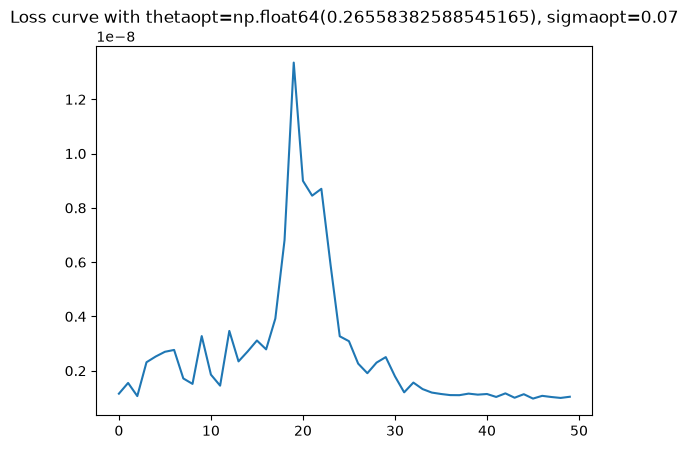

In [11]:
##########################
# LOOCV optimization step
##########################
if hypropt == 1:
    bL = 0.2; bR = 0.3                                 # left and right bounds
    bounds = [bL, bR]                                  # To initialize theta (correlation parameter)
    n_iter = 100
    loomsefn = lambda theta: LOOMSESK2D(theta, ytrue, Kmatfn, sigma = 1.0)
    thetaopt, optscore, history = adamopt(loomsefn, bounds, n_iter = n_iter, stoploss = 50)
    print(f'{thetaopt=}'); print(f'{optscore=:.4f}')
    sigmaopt = LOOVARSK2D(ytrue, Kmatfn, dict(theta = thetaopt,
                                                sigma = 1.0), nugget = 1e-6)
    print(f'{sigmaopt=:.2f}')
    plt.figure()
    if not np.sum(history==1e10) == 0:                  # To check IF the stopping criterion was invoked
        stopindex = int(np.where(history==1e10)[0][0])  # WHERE the stopping criteria was invoked
        plt.plot(range(stopindex - 1), history[:stopindex-1]); plt.title(f'Loss curve with {thetaopt=}, {sigmaopt=:.2f}')
    else: 
        plt.plot(range(n_iter), history); plt.title(f'Loss curve with {thetaopt=}, {sigmaopt=:.2f}')
else: 
    print(f'Using the fixed kernel params (user inputs): {theta=}, {sigma=:.2f}')
    thetaopt = theta; sigmaopt = sigma

## Matrix K (optimal)
K = Kmatfn(dict(theta = thetaopt,                       # LOOCV Optimal Kplus matrix 
                     sigma = 1.0)) 


## Final predictions 

In [12]:
###########################
## Simple Lagrangian Kriging: final prediction
###########################
def LagKrig(Kinv, H, v, ytrue, U, **kwargs):
    '''
    LagKrig
    
    :param Kinv: K inverse
    :param H: H matrix
    :param v: RHS of constraints
    :param ytrue: True observations
    :param U: U matrix
    :param kwargs: Pass UTUinv

    Feel free to pass UTUinv as a keyword argument.
    '''
    if 'UTUinv' in kwargs:
        # print('Using U^T U inverse given')
        UTUinv = kwargs.get('UTUinv')
    else:
        # print('Computing U^T U inverse')
        UTU = U.T @ U
        I = np.eye(UTU.shape[0])
        UTUinv =  np.linalg.solve(UTU, I)
    HKZ = H.T @ Kinv @ ytrue                            # Simple Kriging prediction
    prediction = (U @ UTUinv @ (v - U.T @ HKZ)) + HKZ
    return prediction

################################################
## Simple Lagrangian Kriging: Uncertainty Quantification
################################################
def LagVar(Zpred, Kinv, H, v, ytrue, U, **kwargs):
    '''
    MMSE prediction (Conditional variance approximation)
    
    :param Zpred: Prediction locations and resp. orders of derivatives.
    :param Kinv: K inverse
    :param H: Matrix H
    :param v: RHS of constraints
    :param ytrue: Observed y values
    :param U: Coefficient matrix
    :param kwargs: Extra

    Feel free to pass `UTUinv`, `lamda`, `gamma`, `thetaopt` and `sigmaopt` as a keyword arguments. 
    '''
    theta = 1.0; sigma = 1.0                            # Default. Pass the optimal kernel params as keyword arguments
    if 'UTUinv' in kwargs:
        # print('Using U^T U inverse given')
        UTUinv = kwargs.get('UTUinv')
    else:
        # print('Computing U^T U inverse')
        UTU = U.T @ U
        I = np.eye(UTU.shape[0])
        UTUinv =  np.linalg.solve(UTU, I)               # (U^T U)^{-1} 
    if 'gamma' in kwargs:
        # print('Using gamma value given')
        gamma = kwargs.get('gamma')
    else:
        # print('Computing gamma value')
        gamma = ytrue.T @ Kinv @ ytrue                  # Z^T K^{-1} Z, RKHS norm
    HKZ = H.T @ Kinv @ ytrue                            # H^T K^{-1} Z, Simple Kriging prediction
    if 'lamda' in kwargs:
        # print('Using lambda (Lagrange multipliers) values given')
        lamda = kwargs.get('lamda')
    else:
        # print('Computing lambda values')
        lamda = (1/gamma) * UTUinv @ (v - (U.T @ HKZ))  # Lagrange multipliers
    
    ## Please pass optimal kernel parameters
    if 'thetaopt' in kwargs:
        theta = kwargs.get('thetaopt')
    if 'sigmaopt' in kwargs:
        sigma = kwargs.get('sigmaopt')

    ## final variance equation
    Kstar = CovM(Zpred, kernel = AnalyticalSqExpdiff2D, 
                        theta = theta,                  # Unconditional variance.
                        sigma = sigma) 
    M1 = np.outer(ytrue, lamda) @ U.T
    M2 = (H + M1).T @ Kinv @ (M1 - H)                   # LK contribution
    Var = np.diag(Kstar + M2)
    BaseVar = 1e-5                                      # To make sure Conditional variance estimate is positive. 
    return np.sqrt(Var + BaseVar)  
##########################################

In [13]:
## Matrix H 
params = dict(theta = thetaopt, sigma = 1.0)
CovParam = lambda *Zvals: CovM(*Zvals, kernel = AnalyticalSqExpdiff2D, **params)
H = CovParam(Obs, B)                                          # boundary prediction points.

# Simple Lagrangian Kriging [vhat]
nugget = 1e-10                                                # small nugget for numerical stability.
I = np.eye(K.shape[0]); nI = nugget * I
Kinv = np.linalg.solve(K + nI, I)
yhat = LagKrig(Kinv, H, v, ytrue, U)                          # All predictions (alternating components)
vxhat, vyhat = yhat.reshape((2, p2),
                            order = 'F')

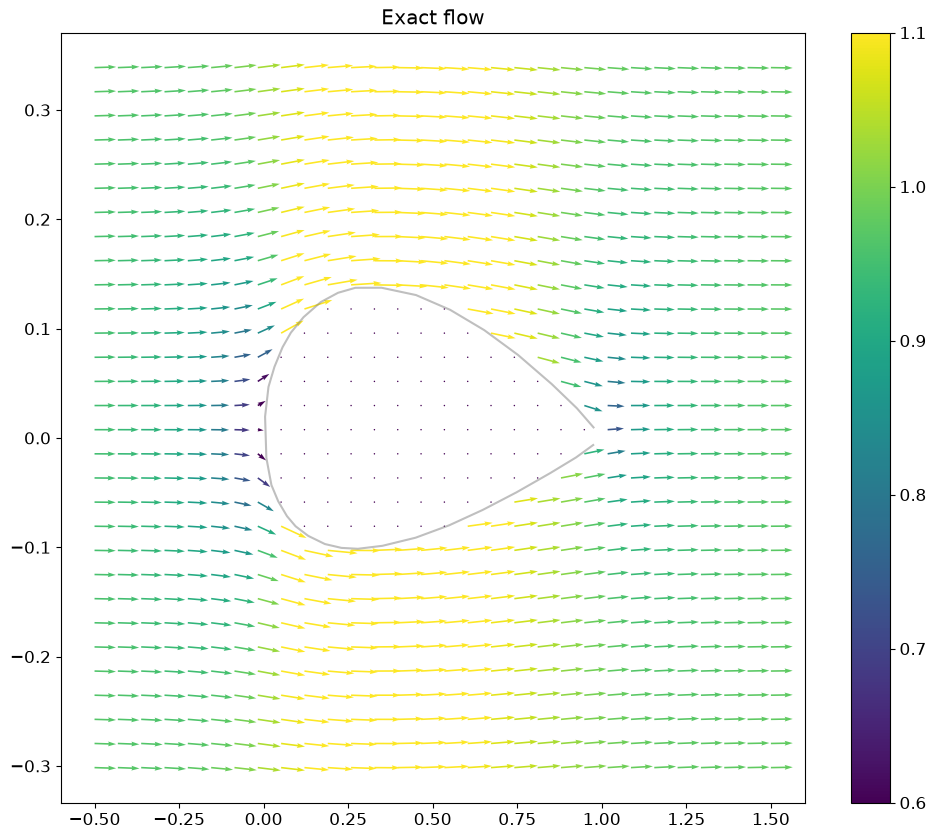

In [14]:
## Visualization true flow
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})    
widf = 1.5
plt.figure(figsize = (12, 10))
plt.cla()
quiverkwargs = dict(pivot = 'tail',
                    scale = 1/0.030, 
                    width = 3.25/(widf*1e3), 
                    clim = (0.6, 1.1))                                  # Colorbar
Q1 = plt.quiver(XX, YY,
                Vx, Vy,
                np.hypot(Vx, Vy), 
                alpha = 1,
                **quiverkwargs) 
plt.colorbar()
plt.plot(XB, YB,
         alpha = 0.5, c = 'grey', label='Obstacle')
plt.title(f'Exact flow')
# plt.xlim(-1,2)
# plt.ylim(-1.4, 1.4)
# if figsave == 1:
#     plt.savefig(IMGPATH+'AirfoilCK.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
plt.show()

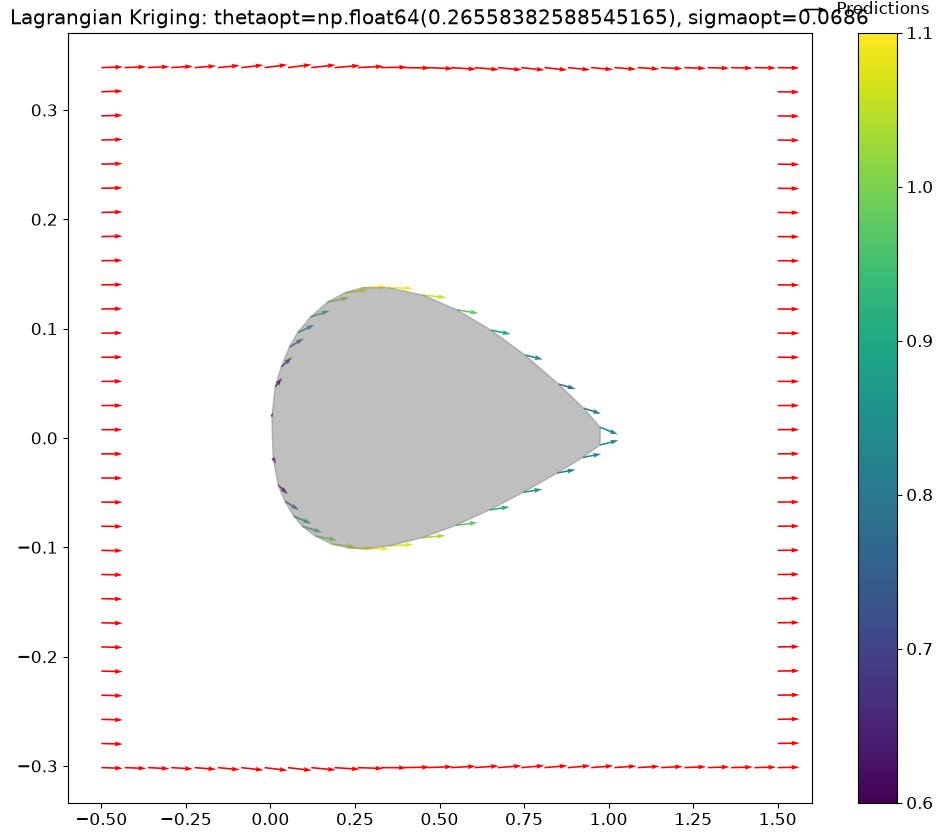

In [15]:
## Visualization Lagrangian Kriging flow prediction
plt.figure(figsize = (12, 10))
plt.cla()
Q2 = plt.quiver(B[::2,0,0], B[::2,0,1],
                vxhat, vyhat,
                np.hypot(vxhat, vyhat), 
                alpha = 1.0,
                **quiverkwargs)
# Q2 = plt.quiver(B[::2,0,0], B[::2,0,1],
#                 yhat[::2], yhat[1::2],
#                 np.hypot(yhat[::2], yhat[1::2]), 
#                 alpha = 1.0,
#                 **quiverkwargs)
plt.colorbar()
Q1 = plt.quiver(XX[mask], YY[mask],
                Vx[mask], Vy[mask],
                # np.hypot(vwx[mask], vwy[mask]), 
                # alpha = 0.5,
                color = 'red', alpha = 1,
                **quiverkwargs) 
plt.quiverkey(Q1, 1.02, 1.05, 1, label='Observations', labelpos = 'E')
plt.quiverkey(Q2, 1.02, 1.03, 1, label='Predictions', labelpos = 'E')
plt.fill(XB, YB,
         alpha = 0.5, c = 'grey', label='Obstacle')
plt.title(f'Lagrangian Kriging: {thetaopt=}, {sigmaopt=:.4f}')
# plt.xlim(min(XX)-0.05, max(XX)+0.1)
# plt.ylim(min(YY)-0.1, max(YY)+0.1)
# if figsave == 1:
#     plt.savefig(IMGPATH+'AirfoilCK.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
plt.show()

## Simple Kriging based interpolation step

In [16]:
# prediction points
q = XX.shape[0]                      # NUM prediction points.
Pred = np.zeros((q, 2, 2))           # initialize the prediction locations. 

# Airfoil shape definition.
airfoilshape = Polygon(np.column_stack([XB, YB]))   # Defining a polygon based on the airfoil profile.
airfoilcontains = lambda x, y: airfoilshape.contains(Point(x, y))   # Function to check if point is within airfoil. 

# Setting the right locations.
Pred[:,0,:] = np.column_stack([XX, YY])

# creating a mask to set predictions inside the airfoil to zero.
withinairfoil = np.array(list(map(airfoilcontains, 
                                    XX, 
                                    YY)))

Iter 1/1000 - LOOMSE: 0.004   lengthscale: 1.720
Iter 2/1000 - LOOMSE: 0.004   lengthscale: 1.710
Iter 3/1000 - LOOMSE: 0.004   lengthscale: 1.703
Iter 4/1000 - LOOMSE: 0.004   lengthscale: 1.694
Iter 5/1000 - LOOMSE: 0.004   lengthscale: 1.688
Iter 6/1000 - LOOMSE: 0.004   lengthscale: 1.682
Iter 7/1000 - LOOMSE: 0.004   lengthscale: 1.675
Iter 8/1000 - LOOMSE: 0.004   lengthscale: 1.670
Iter 9/1000 - LOOMSE: 0.004   lengthscale: 1.667
Iter 10/1000 - LOOMSE: 0.004   lengthscale: 1.664
Iter 11/1000 - LOOMSE: 0.004   lengthscale: 1.661
Iter 12/1000 - LOOMSE: 0.004   lengthscale: 1.656
Iter 13/1000 - LOOMSE: 0.004   lengthscale: 1.653
Iter 14/1000 - LOOMSE: 0.004   lengthscale: 1.652
Iter 15/1000 - LOOMSE: 0.004   lengthscale: 1.651
Iter 16/1000 - LOOMSE: 0.004   lengthscale: 1.650
Iter 17/1000 - LOOMSE: 0.004   lengthscale: 1.651
Iter 18/1000 - LOOMSE: 0.004   lengthscale: 1.650
Iter 19/1000 - LOOMSE: 0.004   lengthscale: 1.649
Iter 20/1000 - LOOMSE: 0.004   lengthscale: 1.649
Iter 21/1

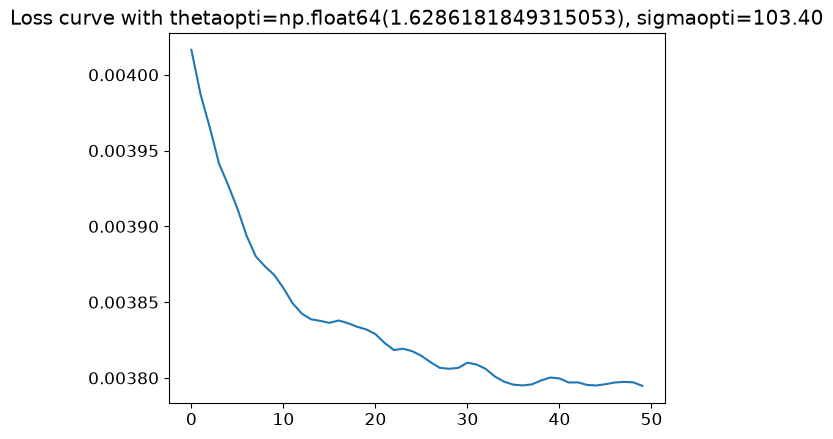

In [17]:
# kernel hyperparameters
thetaInterpol = 1.0
sigmaInterpol = 1.0

# Grid prediction points.
PredOut = Pred[~withinairfoil]                              # Prediction locations outside the airfoil.     

TotObs = np.zeros((nobs + p2,                               # Total observations locations: considering LK predictions as true observations 
                   2, 2))                                   # Order of derivatives kept zero since we are using the undifferentiated kernel.                                   
TotObs[:nobs,0,:] = Obs[:nobs,0,:]                          # Original observation locations
TotObs[nobs:,0,:] = B[::2,0,:]                              # Boundary prediction locations                                                 
Vvect = np.vstack([*ytrue.reshape((-1, 2),                  # Adding an extra axis, to collect vx and vy as separate columns and then flattening. 
                            order='F').flatten(),
                   *yhat])                                  # Combined observations. 

## Interpolation K matrix
def Kinterpol(params):
    K = CovM(TotObs, kernel = AnalyticalSqExpdiff2D, **params)
    Kkron = np.kron(K, np.eye(2))                           # K matrix with zero cross-covariances between vx and vy. Assuming criss-cross arrangement of vx and vy vectors.
    return Kkron

if hypropt == 1:
    bL = 1.0; bR = 2.0                                      # left and right bounds
    bounds = [bL, bR]                                       # To initialize theta (correlation parameter)
    n_iter = 1000
    loomsefn = lambda theta: LOOMSESK2D(theta, Vvect, Kinterpol, sigma = 1.0, nugget = 1e-10)
    thetaopti, optscore, history = adamopt(loomsefn, bounds, n_iter = n_iter)
    print(f'{thetaopti=:.2f}'); print(f'{optscore=:.4f}')
    sigmaopti = LOOVARSK2D(Vvect, Kinterpol, dict(theta = thetaopti, sigma = 1.0), nugget = 1e-6)
    # plt.plot(range(n_iter), history); plt.show()            # To visualize LOOCV loss curve
    if not np.sum(history==1e10) == 0:                        # To check IF the stopping criterion was invoked
        stopindex = int(np.where(history==1e10)[0][0])        # WHERE the stopping criteria was invoked
        plt.plot(range(stopindex - 1), history[:stopindex-1]); plt.title(f'Loss curve with {thetaopti=}, {sigmaopti=:.2f}')
    else: 
        plt.plot(range(n_iter), history); plt.title(f'Loss curve with {thetaopti=}, {sigmaopti=:.2f}')
    print(f'{sigmaopti=:.2f}')
else: 
    print(f'Using the fixed kernel params (user inputs): {thetaInterpol=:.2f}, {sigmaInterpol=:.2f}')
    thetaopti = thetaInterpol; sigmaopti = sigmaInterpol

In [18]:
# TEST : Arrangement of the ytrue vector. 
# ytrue.reshape((-1, 2), 
#               order='F').flatten()

In [28]:
## Optimal interpolation matrices.
params = dict(theta = thetaopti, sigma = sigmaopti)          # Optimal params
Kkron = Kinterpol(params)
H = CovM(TotObs, PredOut, kernel = AnalyticalSqExpdiff2D, **params)
Hkron = np.kron(H, np.eye(2))

# Interpolated predictions
nugget = 1e-5
I = np.eye(Kkron.shape[0]); nI = nugget * I
Kkroninv = np.linalg.solve(Kkron + nI, I)
Vstarkron = Hkron.T @ Kkroninv @ Vvect                     # Simple Kriging predictions
Vstarkron = Vstarkron.reshape(-1,2)                        # New axis indicating Vx, Vy

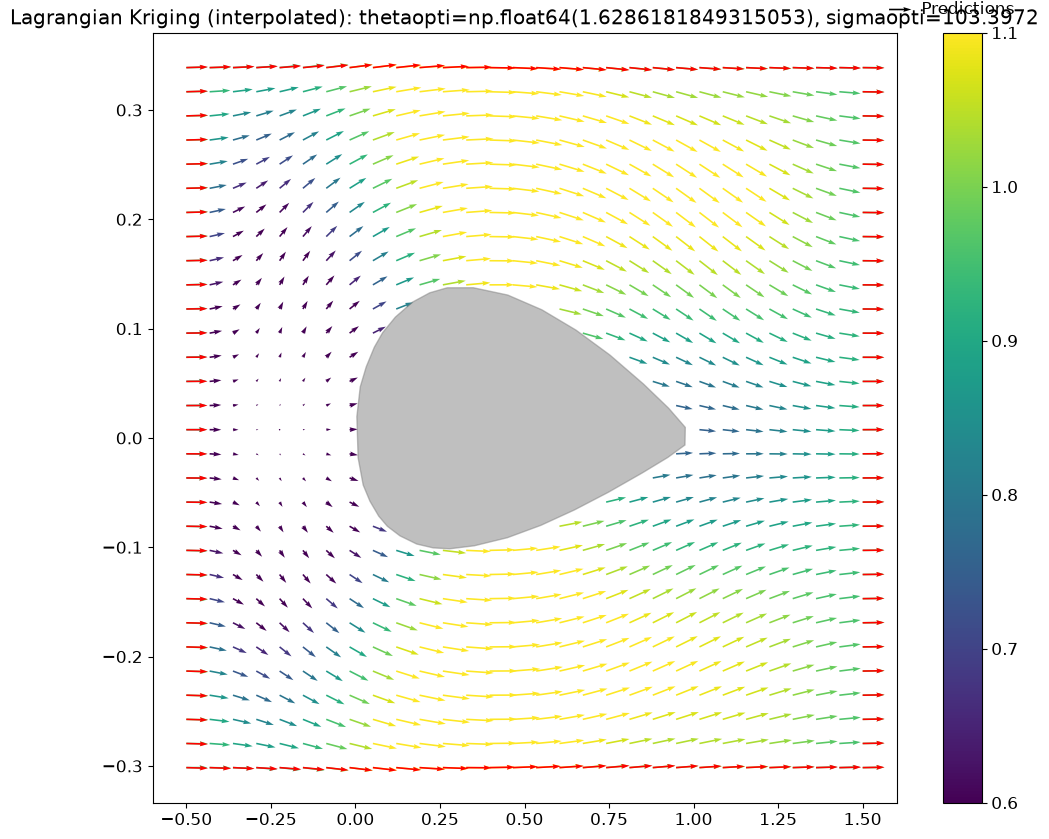

In [29]:
## Interpolated predictions
plt.figure(figsize = (12, 10))
plt.cla()
qout = int(PredOut.shape[0]/2)
Q2 = plt.quiver(PredOut[:,0,0], PredOut[:,0,1],
                Vstarkron[:,0], Vstarkron[:,1],
                np.hypot(Vstarkron[:,0], Vstarkron[:,1]), 
                alpha = 1.0,
                **quiverkwargs)
# Q2 = plt.quiver(B[::2,0,0], B[::2,0,1],
#                 yhat[::2], yhat[1::2],
#                 np.hypot(yhat[::2], yhat[1::2]), 
#                 alpha = 1.0,
#                 **quiverkwargs)
plt.colorbar()
Q1 = plt.quiver(XX[mask], YY[mask],
                Vx[mask], Vy[mask],
                # np.hypot(vwx[mask], vwy[mask]), 
                # alpha = 0.5,
                color = 'red', alpha = 1,
                **quiverkwargs) 
plt.quiverkey(Q1, 1.02, 1.05, 1, label='Observations', labelpos = 'E')
plt.quiverkey(Q2, 1.02, 1.03, 1, label='Predictions', labelpos = 'E')
plt.fill(XB, YB,
         alpha = 0.5, c = 'grey', label='Obstacle')
plt.title(f'Lagrangian Kriging (interpolated): {thetaopti=}, {sigmaopti=:.4f}')
# plt.xlim(min(XX)-0.05, max(XX)+0.1)
# plt.ylim(min(YY)-0.1, max(YY)+0.1)
# if figsave == 1:
#     plt.savefig(IMGPATH+'AirfoilCK.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
plt.show()

In [21]:
# min(np.diag(Kkron))/sigmaopti